# 03. Watershed Hydrology, 10-Year C&V & Coupling (Xindian River)

- **Goal:** Validate multi-year weather forcing, enforce disjoint catchment bindings, and check 10-year GWLF high/low-flow skill.
- **Case & Window (Repo-Only — Not in Paper):** Taiwan Xindian River (`U1, U2, D1, D2`; `2015–2025`, TFRA rain + ERA5 temp/PET).
- **Pass Criterion:** `0` overlapping units; live HydroCNHS matches coupled `inflows.csv`.

*Runs 100% offline (`0` API cost).*

In [1]:
import json
from pathlib import Path
import sys
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h
from llm_reservoir_agent.weather import load_weather, simulate_weather, validate_bindings

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Check Disjoint Subbasin Bindings & 11-Year Forcing

Ensure `feitsui_local` (`U1–U2` Beishi) and `zhitan_local` (`D1–D2` Nanshi) never double-count upstream runoff.

In [2]:
mr_dir = REPO_ROOT / "examples" / "multi_reservoir"
hyd_dir = mr_dir / "hydrology"
hyd_spec = yaml.safe_load((hyd_dir / "hydrology.yaml").read_text(encoding="utf-8"))
catch_cfg = yaml.safe_load((hyd_dir / "xindian_catchments.yaml").read_text(encoding="utf-8"))

weather = load_weather(hyd_spec, hyd_dir)
unused = validate_bindings(weather, routing_nodes=["feitsui_local", "zhitan_local", "xindian_outlet"])
print(f"Forcing days : {len(weather['dates'])} ({weather['dates'][0]} to {weather['dates'][-1]})")
print(f"Subbasins    : {weather['units']} | Unused units: {unused} | Zero double-counting OK")
print("Bindings     :", hyd_spec["inflow_bindings"])

Forcing days : 4018 (2015-01-01 to 2025-12-31)
Subbasins    : ['U1', 'U2', 'D1', 'D2'] | Unused units: [] | Zero double-counting OK
Bindings     : {'feitsui_local': {'routed': 'U1'}, 'zhitan_local': {'routed': 'D1'}, 'xindian_outlet': {'constant': 0}}


## 2. Run Native HydroCNHS & Check 10-Year C&V Parity

Execute `simulate_weather`, verify coupling parity against `inflows.csv`, and inspect `r, alpha, beta` across `2023–2025`.

In [3]:
sim_res = simulate_weather(weather, REPO_ROOT)
sim_df = pd.DataFrame({"date": weather["dates"], "feitsui_sim": sim_res["routed"]["U1"], "zhitan_sim": sim_res["routed"]["D1"]})
pub = pd.read_csv(mr_dir / "inflows.csv").pivot(index="date", columns="node", values="local_inflow_cms").reset_index()
chk = pub.merge(sim_df, on="date", how="inner")
print(f"Coupling parity max |diff| : feitsui={np.max(np.abs(chk['feitsui_local'] - chk['feitsui_sim'])):.2e} | zhitan={np.max(np.abs(chk['zhitan_local'] - chk['zhitan_sim'])):.2e} m3/s")

obs_cv = pd.read_csv(hyd_dir / "cv_observations.csv.gz")
m_val = sim_df.merge(obs_cv, on="date", how="inner")
m_val["date_dt"] = pd.to_datetime(m_val["date"])
val_23_25 = m_val[(m_val["date"] >= "2023-01-01") & (m_val["date"] <= "2025-12-31")]
sc_f = h.kge_components(val_23_25["feitsui_sim"], val_23_25["feitsui_inflow_cms"])
sc_n = h.kge_components(val_23_25["zhitan_sim"], val_23_25["zhitan_local_nanshi_cms"])
print("Val 2023-2025 Feitsui :", {k: round(v, 3) for k, v in sc_f.items()})
print("Val 2023-2025 Nanshi  :", {k: round(v, 3) for k, v in sc_n.items()})


Coupling parity max |diff| : feitsui=4.96e-07 | zhitan=5.00e-07 m3/s
Val 2023-2025 Feitsui : {'kge': 0.912, 'r': 0.948, 'alpha': 1.061, 'beta': 1.037, 'nse': 0.886, 'rmse': 17.378}
Val 2023-2025 Nanshi  : {'kge': 0.844, 'r': 0.849, 'alpha': 1.039, 'beta': 0.991, 'nse': 0.684, 'rmse': 32.856}


## 3. Diagnose High-Flow Peaks, Low-Flow Tail & 2025 Closure

Inspect KGE `(r, alpha, beta)` decomposition alongside Out-of-Sample Flow-Duration Curves (`2023–2025`) and `2025` cumulative closure.

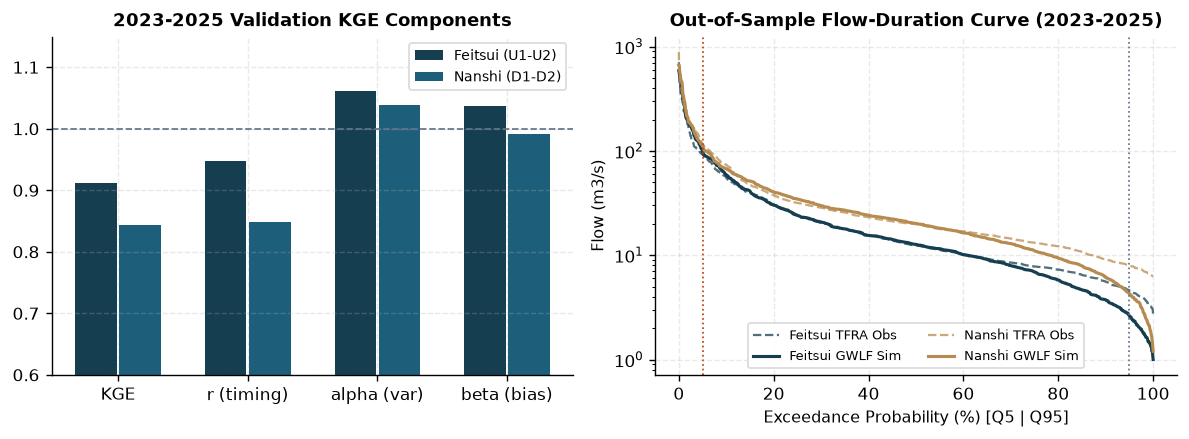

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.6))
comps = ["kge", "r", "alpha", "beta"]
x = np.arange(len(comps))
ax1.bar(x - 0.17, [sc_f[k] for k in comps], width=0.32, color=C["navy"], label="Feitsui (U1-U2)")
ax1.bar(x + 0.17, [sc_n[k] for k in comps], width=0.32, color=C["teal"], label="Nanshi (D1-D2)")
ax1.axhline(1.0, color=C["muted"], ls="--", lw=1.0)
ax1.set_xticks(x); ax1.set_xticklabels(["KGE", "r (timing)", "alpha (var)", "beta (bias)"])
ax1.set_ylim(0.6, 1.15); ax1.set_title("2023-2025 Validation KGE Components"); ax1.legend(fontsize=8)

for s_col, o_col, col, lbl in [
    ("feitsui_sim", "feitsui_inflow_cms", C["navy"], "Feitsui"),
    ("zhitan_sim", "zhitan_local_nanshi_cms", C["gold"], "Nanshi"),
]:
    s_sorted = np.sort(val_23_25[s_col].dropna().to_numpy())[::-1]
    o_sorted = np.sort(val_23_25[o_col].dropna().to_numpy())[::-1]
    p_s = np.linspace(0, 100, len(s_sorted))
    p_o = np.linspace(0, 100, len(o_sorted))
    ax2.semilogy(p_o, np.maximum(o_sorted, 0.1), color=col, ls="--", lw=1.3, alpha=0.75, label=f"{lbl} TFRA Obs")
    ax2.semilogy(p_s, np.maximum(s_sorted, 0.1), color=col, lw=1.8, label=f"{lbl} GWLF Sim")
ax2.axvline(5, color=C["coral"], ls=":", lw=1.0); ax2.axvline(95, color=C["muted"], ls=":", lw=1.0)
ax2.set_xlabel("Exceedance Probability (%) [Q5 | Q95]"); ax2.set_ylabel("Flow (m3/s)")
ax2.set_title("Out-of-Sample Flow-Duration Curve (2023-2025)"); ax2.legend(ncol=2, fontsize=7.5)
plt.tight_layout(); plt.show()

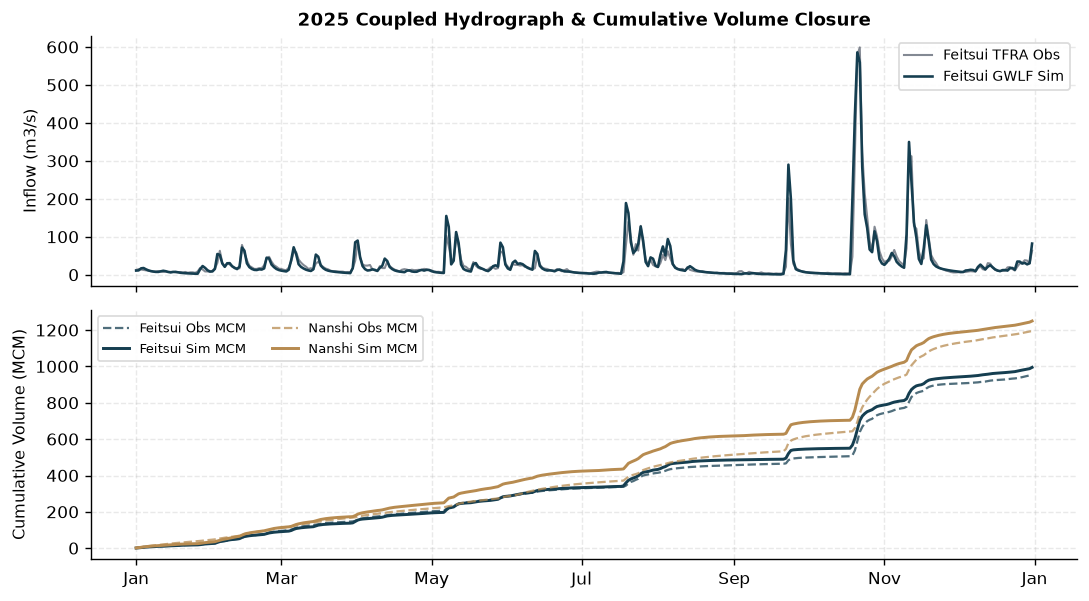

In [5]:
y25 = m_val[(m_val["date"] >= "2025-01-01") & (m_val["date"] <= "2025-12-31")].copy()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.8, 4.9), sharex=True)
ax1.plot(y25["date_dt"], y25["feitsui_inflow_cms"], color=C["obs"], alpha=0.55, lw=1.2, label="Feitsui TFRA Obs")
ax1.plot(y25["date_dt"], y25["feitsui_sim"], color=C["navy"], lw=1.5, label="Feitsui GWLF Sim")
ax1.set_ylabel("Inflow (m3/s)"); ax1.set_title("2025 Coupled Hydrograph & Cumulative Volume Closure")
ax1.legend(loc="upper right", fontsize=8)

for s_col, o_col, col, lbl in [
    ("feitsui_sim", "feitsui_inflow_cms", C["navy"], "Feitsui"),
    ("zhitan_sim", "zhitan_local_nanshi_cms", C["gold"], "Nanshi"),
]:
    ax2.plot(y25["date_dt"], np.cumsum(y25[o_col].fillna(0) * 86400 / 1e6), color=col, ls="--", lw=1.3, alpha=0.75, label=f"{lbl} Obs MCM")
    ax2.plot(y25["date_dt"], np.cumsum(y25[s_col] * 86400 / 1e6), color=col, lw=1.7, label=f"{lbl} Sim MCM")
ax2.set_ylabel("Cumulative Volume (MCM)"); ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax2.legend(loc="upper left", ncol=2, fontsize=7.5); plt.tight_layout(); plt.show()

- **Peak & baseflow balance:** FDC tracks `Q5` flood peaks and `Q95` low flows without systematic volume drift (`beta` near `1.0`).
- **Coupling integrity:** Live `simulate_weather` matches `inflows.csv` cleanly for downstream runs.

## 4. Adapt to Your Basin

- **Hydrology prep:** Run `reservoir-experiment prepare <yaml>` on an agent-free HydroCNHS model (`ABM: null`).
- **Forcing units:** Supply `mm/day`, `degC`, `cm/day` with a warm-up year before `start_date`.
- **Disjoint bindings:** Map terminal outlets (`routed:` / `runoff:`) without overlap.

Next: [Module 04](../04_multi_reservoir_hybrid_cascade/04_xindian_hybrid_cascade.ipynb)